# Python Data Cleaning and Visualization - 2026-10-23 - JerDea2641

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

file_path = r"C:\Users\Jeremy\Downloads\AirBnBSummary_v2.xlsx"
df = pd.read_excel(file_path)

display(df.head())
print(df.columns.tolist())

,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
0,7909479,41706311,David,Downtown,Entire home/apt,107.0,30,27,365.0,NaN
1,15966488,103700433,Erin,Downtown,Entire home/apt,100.0,1,250,74.0,NaN
2,19859814,103700433,Erin,Downtown,Entire home/apt,100.0,1,309,79.0,NaN
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,NaN
4,21712505,103700433,Erin,Downtown,Entire home/apt,100.0,1,178,68.0,NaN


['id', 'host_id', 'host_name', 'neighbourhood', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'availability_365', '<StudentID>']


In [12]:
#Remove duplicate entries
df = df.drop_duplicates()

# Correct room type spelling
df["room_type"] = df["room_type"].replace("Private room", "Private Room")

In [13]:
# Fill missing values
for column in df.columns:
    if df[column].isnull().any():
        if pd.api.types.is_numeric_dtype(df[column]):
            df[column] = df[column].fillna(df[column].median())
        else:
            mode_value = df[column].mode()
            if not mode_value.empty:
                df[column] = df[column].fillna(mode_value[0])


# Remove outliers using the IQR method
numerical_columns = df.select_dtypes(include="number").columns
outlier_filter = pd.Series(False, index=df.index)

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_filter |= (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

df = df[~outlier_filter]

print("Remaining listings:", len(df))


Remaining listings: 1205


In [14]:
# Save the cleaned data frame to a new Excel spreadsheet
cleaned_file_path = r"C:\Users\Jeremy\Downloads\AirBnBSummary_v2_Python_Cleaned.xlsx"
df.to_excel(cleaned_file_path, index=False)

In [15]:
# Display the following statistics
print("Total count of listings:", len(df))
print("Minimum price:", df["price"].min())
print("Maximum price:", df["price"].max())
print("Mean price of listings:", df["price"].mean())
print("Median of number_of_reviews:", df["number_of_reviews"].median())
print("Mode of minimum_nights:", df["minimum_nights"].mode().iloc[0])
print("Standard Deviation of price:", df["price"].std())
print("Correlation between price and availability_365:", df["price"].corr(df["availability_365"]))

Total count of listings: 1205
Minimum price: 32.0
Maximum price: 308.0
Mean price of listings: 132.18008298755186
Median of number_of_reviews: 20.0
Mode of minimum_nights: 1
Standard Deviation of price: 62.533791011464615
Correlation between price and availability_365: 0.09281345709052662


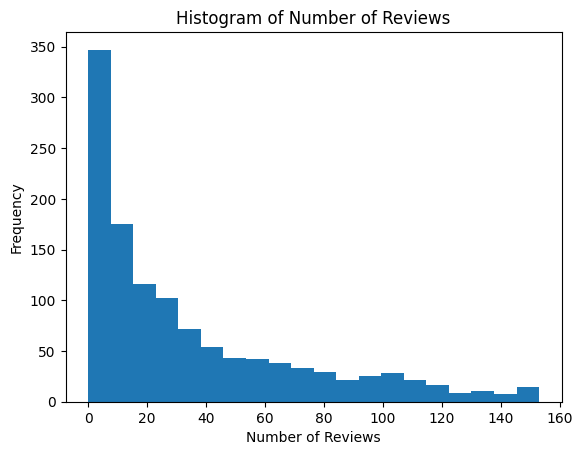

In [16]:
# Histogram of number_of_reviews
plt.hist(df["number_of_reviews"], bins=20)
plt.xlabel("Number of Reviews")
plt.ylabel("Frequency")
plt.title("Histogram of Number of Reviews")
plt.show()

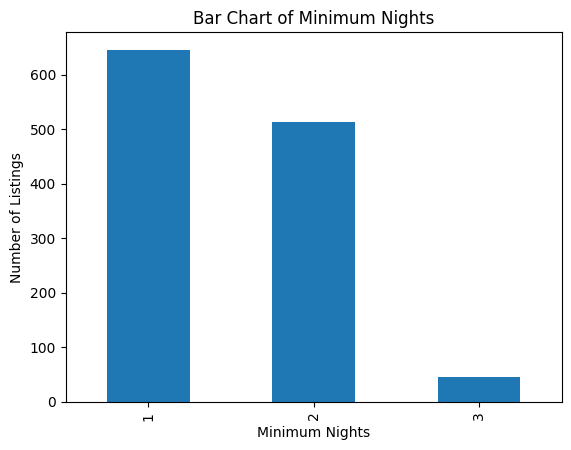

In [17]:
# Bar Chart of minimum_nights
df["minimum_nights"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")
plt.title("Bar Chart of Minimum Nights")
plt.show()

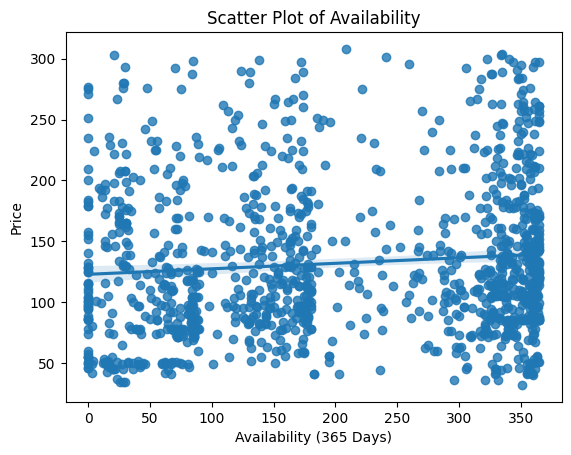

In [21]:
# Scatter Plot of availability_365
sns.regplot(x="availability_365", y="price", data=df)

plt.xlabel("Availability (365 Days)")
plt.ylabel("Price")
plt.title("Scatter Plot of Availability")
plt.show()

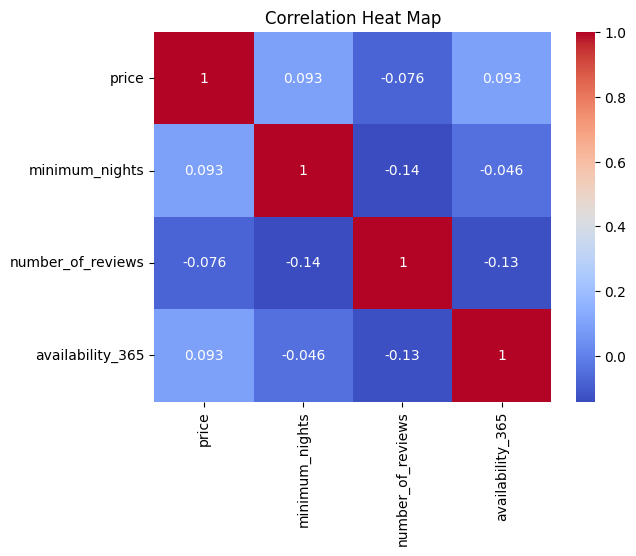

In [19]:
# Heat map of correlations
correlation_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "availability_365"
]

correlation_matrix = df[correlation_columns].corr()

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heat Map")
plt.show()